# Resting EEG frontal alpha asymmetry in major depressive disorder

**Question.** During eyes-closed rest, does average frontal alpha asymmetry (FAA) differ between people labeled as having major depressive disorder (MDD) and healthy controls in the Mumtaz dataset?

**Design.** Exploratory, cross-sectional secondary analysis. The unit of inference is the participant. The primary endpoint is `ln(alpha power at F4) − ln(alpha power at F3)`. A two-sided Welch test estimates the MDD-minus-control contrast. Classification is exploratory and uses separate evaluation folds at the participant level.

**Source.** Wajid Mumtaz (2016), *MDD Patients and Healthy Controls EEG Data (New)*, [Figshare 4244171, version 2](https://doi.org/10.6084/m9.figshare.4244171.v2), CC BY 4.0. This notebook uses the original EDF deposit and the publisher's filename labels. The [acquisition paper](https://doi.org/10.1016/j.bspc.2016.07.006) provides study context. The [FAA methods primer](https://doi.org/10.1016/j.ijpsycho.2016.11.005) and [depression meta-analysis](https://doi.org/10.1016/j.nicl.2017.07.006) provide methodological and scientific context.

## Run it locally

Use Python 3.12 in a virtual environment. Install the versions below, then open the notebook in JupyterLab or VS Code with that environment selected. Run all cells. The first run needs internet access to Figshare and about 190 MB for cached EDFs. You can set `EEG_CACHE_DIR` and `EEG_OUTPUT_DIR` to override the default local folders.

```bash
python -m venv .venv
source .venv/bin/activate
python -m pip install jupyterlab ipykernel==6.30.1 mne==1.10.2 numpy==2.3.5 scipy==1.17.0 pandas==2.2.3 matplotlib==3.10.8 scikit-learn==1.8.0 threadpoolctl==3.6.0
jupyter lab
```

In [1]:
%matplotlib inline
import hashlib
import json
import os
import platform
import re
import time
from concurrent.futures import ThreadPoolExecutor
from importlib.metadata import version
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, permutation_test_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

SEED = 42
ARTICLE_ID = 4244171
ARTICLE_VERSION = 2
ARTICLE_DOI = f"10.6084/m9.figshare.{ARTICLE_ID}.v{ARTICLE_VERSION}"
ARTICLE_URL = f"https://api.figshare.com/v2/articles/{ARTICLE_ID}/versions/{ARTICLE_VERSION}"
CACHE = Path(os.environ.get("EEG_CACHE_DIR", "eeg_data"))
OUTPUT = Path(os.environ.get("EEG_OUTPUT_DIR", "eeg_results"))
CACHE.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
GROUPS = ["Control", "MDD"]
CHANNELS = (
    "FP1", "FP2", "F7", "F3", "FZ", "F4", "F8", "T3", "C3", "CZ",
    "C4", "T4", "T5", "P3", "PZ", "P4", "T6", "O1", "O2",
)
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}
SFREQ = 256
WINDOW_S = 4
HOP_S = 2
EDGE_S = 2
MIN_WINDOWS = 20
FLAT_UV = 0.5
PRIMARY_UV = 200
STRICT_UV = 150
N_PERMUTATIONS = 999

mne.set_log_level("ERROR")
versions = {
    "Python": platform.python_version(),
    **{name: version(name) for name in (
        "mne", "numpy", "scipy", "pandas", "matplotlib", "scikit-learn", "threadpoolctl"
    )},
}
print(", ".join(f"{name} {value}" for name, value in versions.items()))

Python 3.12.14, mne 1.10.2, numpy 2.3.5, scipy 1.17.0, pandas 2.2.3, matplotlib 3.10.8, scikit-learn 1.8.0, threadpoolctl 3.6.0


## 1. Assemble the eyes-closed cohort

Parse diagnosis and condition from the original filenames, accepting the inconsistent spacing in the deposit. Keep group and subject number together because numeric IDs are reused across groups. For each EDF, use the computed Figshare MD5 if available and the supplied MD5 otherwise. Compare checksums within the eyes-closed condition. Keep the lower numeric ID for a same-group alias and flag it for a sensitivity check. Fail on conflicting group labels or repeated subject keys.

Six listed files returned HTTP 404 and had no server-computed MD5 at analysis time. The snapshot exclusions are pinned by file ID below so reruns use the same cohort. Downloads for the remaining files are cached and verified against size and checksum. Any failed required download stops execution.

In [2]:
def fetch_bytes(url, expected_size=None, expected_md5=None):
    for attempt in range(3):
        try:
            request = Request(url, headers={"User-Agent": "EEG-FAA-reproducibility/1.0"})
            with urlopen(request, timeout=45) as response:
                data = response.read()
            if expected_size is not None and len(data) != expected_size:
                raise ValueError(f"Unexpected size for {url}")
            if expected_md5 is not None and hashlib.md5(data).hexdigest() != expected_md5:
                raise ValueError(f"Checksum mismatch for {url}")
            return data
        except (OSError, ValueError):
            if attempt == 2:
                raise
            time.sleep(attempt + 1)


def write_cache(path, data):
    temp_path = path.with_suffix(path.suffix + ".part")
    temp_path.write_bytes(data)
    temp_path.replace(path)


metadata_path = CACHE / f"figshare-{ARTICLE_ID}-v{ARTICLE_VERSION}.json"
if not metadata_path.exists():
    write_cache(metadata_path, fetch_bytes(ARTICLE_URL))
article = json.loads(metadata_path.read_text(encoding="utf-8"))
assert (article["id"], article["version"], article["doi"]) == (
    ARTICLE_ID, ARTICLE_VERSION, ARTICLE_DOI
)

file_pattern = re.compile(r"(H|MDD)\s+S(\d+)\s+(EC|EO|TASK)\.edf", re.IGNORECASE)
rows = []
for item in article["files"]:
    match = file_pattern.fullmatch(item["name"])
    if match is None or match[3].upper() != "EC":
        continue
    label, number = match[1].upper(), int(match[2])
    checksum = item["computed_md5"] or item["supplied_md5"]
    assert re.fullmatch(r"[a-f0-9]{32}", checksum), item["name"]
    rows.append({
        "subject": f"{label}-S{number:02d}",
        "group": "Control" if label == "H" else "MDD",
        "number": number,
        "filename": item["name"],
        "file_id": item["id"],
        "size": item["size"],
        "url": item["download_url"],
        "md5": checksum,
    })

UNAVAILABLE_IDS = {6921113, 6921167, 6921410, 6921446, 6921485, 6921521}
manifest = pd.DataFrame(rows).sort_values(["group", "number"]).reset_index(drop=True)
assert len(manifest) == 64 and manifest["subject"].is_unique, "Unexpected snapshot inventory"
assert manifest.groupby("md5")["group"].nunique().max() == 1, "Cross-group file alias"
manifest["has_alias"] = manifest["md5"].duplicated(keep=False)
manifest["retained_subject"] = manifest.groupby("md5")["subject"].transform("first")
manifest["excluded_alias"] = manifest["subject"] != manifest["retained_subject"]
manifest["unavailable_at_analysis"] = manifest["file_id"].isin(UNAVAILABLE_IDS)
assert manifest["unavailable_at_analysis"].sum() == len(UNAVAILABLE_IDS)
assert not (manifest["excluded_alias"] & manifest["unavailable_at_analysis"]).any()
candidates = manifest.loc[~manifest["excluded_alias"] & ~manifest["unavailable_at_analysis"]].copy()

print(f"{len(article['files'])} deposited files, including {len(manifest)} eyes-closed EDFs.")
display(manifest.loc[manifest["has_alias"],
                     ["filename", "file_id", "md5", "retained_subject", "excluded_alias"]])
display(manifest.loc[manifest["unavailable_at_analysis"], ["filename", "file_id"]])
display(pd.DataFrame({
    "eyes_closed_files": manifest.groupby("group").size(),
    "unavailable": manifest.groupby("group")["unavailable_at_analysis"].sum(),
    "duplicate_alias_removed": manifest.groupby("group")["excluded_alias"].sum(),
    "eligible_for_quality_control": candidates.groupby("group").size(),
}))

193 deposited files, including 64 eyes-closed EDFs.


,filename,file_id,md5,retained_subject,excluded_alias
26,H S27 EC.edf,6921248,723217c6472d66e05cfef4fb122ccafe,H-S27,False
29,H S30 EC.edf,6921272,723217c6472d66e05cfef4fb122ccafe,H-S27,True
62,MDD S33 EC.edf,6921674,4c16e8636fca72ae59711c0ba803349f,MDD-S33,False
63,MDD S34 EC.edf,6921683,4c16e8636fca72ae59711c0ba803349f,MDD-S33,True


,filename,file_id
11,H S12 EC.edf,6921113
17,H S18 EC.edf,6921167
33,MDD S4 EC.edf,6921410
37,MDD S8 EC.edf,6921446
41,MDD S12 EC.edf,6921485
45,MDD S16 EC.edf,6921521


,eyes_closed_files,unavailable,duplicate_alias_removed,eligible_for_quality_control
group,,,,
Control,30,2,1,27
MDD,34,4,1,29


In [3]:
def verified_edf(row):
    path = CACHE / f"{row.file_id}.edf"
    if path.is_file() and path.stat().st_size == row.size:
        with path.open("rb") as stream:
            if hashlib.file_digest(stream, "md5").hexdigest() == row.md5:
                return path
    write_cache(path, fetch_bytes(row.url, row.size, row.md5))
    return path


with ThreadPoolExecutor(max_workers=6) as pool:
    edf_paths = list(pool.map(verified_edf, candidates.itertuples(index=False)))

print(f"Verified {len(edf_paths)} EDFs ({candidates['size'].sum() / 1e6:.1f} MB).")

Verified 56 EDFs (188.0 MB).


## 2. Preprocess and extract one feature row per participant

Use the same 19 scalp electrodes for every recording. Strip EDF label prefixes and reference suffixes, retain the common montage and remove auxiliary channels. Apply MNE's zero-phase 1–40 Hz FIR filter, then subtract the across-channel average at each time point. Trim two seconds at each end and form four-second windows every two seconds. The filter transition widths are 1 Hz and 10 Hz.

Reject a window if any channel has a peak-to-peak range below 0.5 µV in the filtered native-reference signal or above 200 µV in the filtered, average-referenced signal. Reject windows overlapping a BAD/EDGE annotation and require at least 20 usable windows. The main threshold is a heuristic for gross artifact, and the stricter 150 µV threshold is a sensitivity analysis. A separate sensitivity estimate keeps the original EDF reference and the same primary clean windows.

Average Hamming-tapered modified periodograms from retained windows to estimate each participant's PSD on a 0.25 Hz grid. Sum the density bins over the half-open delta [1, 4), theta [4, 8), alpha [8, 13), and beta [13, 30) Hz bands and multiply by bin width for power in V². Within the alpha band, the integration and the guide's mean density differ by a fixed factor that cancels in the log ratio.

In [4]:
def band_features(windows):
    window_samples = WINDOW_S * SFREQ
    psd, frequencies = mne.time_frequency.psd_array_welch(
        windows, sfreq=SFREQ, fmin=1.0, fmax=40.0,
        n_fft=window_samples, n_per_seg=window_samples, n_overlap=0,
        window="hamming", average="mean", remove_dc=True, verbose="ERROR",
    )
    spectrum = psd.mean(axis=0)
    bin_width = frequencies[1] - frequencies[0]
    powers = {
        band: spectrum[:, (frequencies >= lo) & (frequencies < hi)].sum(axis=1) * bin_width
        for band, (lo, hi) in BANDS.items()
    }
    if any(np.any(~np.isfinite(values) | (values <= 0)) for values in powers.values()):
        raise ValueError("Nonpositive or invalid band power")
    alpha = powers["alpha"]
    faa = np.log(alpha[CHANNELS.index("F4")]) - np.log(alpha[CHANNELS.index("F3")])
    return faa, powers, spectrum, frequencies


def participant_features(row, path):
    raw = mne.io.read_raw_edf(path, preload=False, infer_types=False, verbose="ERROR")
    montage = {}
    for original in raw.ch_names:
        match = re.fullmatch(r"EEG\s+([A-Z0-9]+)-[A-Z0-9]+", original.upper())
        if match and match[1] in CHANNELS:
            if match[1] in montage:
                raise ValueError(f"Ambiguous scalp label {match[1]} in {row.filename}")
            montage[match[1]] = original

    audit = {
        "subject": row.subject, "group": row.group, "file_id": row.file_id,
        "has_alias": row.has_alias, "duration_s": raw.n_times / raw.info["sfreq"],
        "sampling_hz": raw.info["sfreq"], "source_channels": len(raw.ch_names),
        "candidate_windows": 0, "clean_windows": 0, "strict_windows": 0,
        "accepted_fraction": np.nan, "status": "pending",
    }
    if set(montage) != set(CHANNELS) or raw.info["sfreq"] != SFREQ:
        audit["status"] = "unexpected montage or sampling rate"
        return audit, None

    raw.pick(list(montage.values()))
    raw.rename_channels({source: canonical for canonical, source in montage.items()})
    raw.reorder_channels(list(CHANNELS)).load_data()
    window_samples = WINDOW_S * SFREQ
    hop_samples = HOP_S * SFREQ
    edge_samples = EDGE_S * SFREQ
    starts = np.arange(edge_samples, raw.n_times - edge_samples - window_samples + 1, hop_samples)
    audit["candidate_windows"] = len(starts)
    if len(starts) < MIN_WINDOWS or not np.isfinite(raw.get_data()).all():
        audit["status"] = "short or nonfinite recording"
        return audit, None

    # The digest detects matching opening scalp signals after EDF decoding.
    head = np.ascontiguousarray(raw.get_data(stop=60 * SFREQ), dtype="<f8")
    audit["signal_head_sha256"] = hashlib.sha256(head.tobytes()).hexdigest()
    raw.filter(
        1.0, 40.0, l_trans_bandwidth=1.0, h_trans_bandwidth=10.0,
        fir_design="firwin", fir_window="hamming", phase="zero", verbose="ERROR",
    )
    native = raw.get_data(reject_by_annotation="NaN")
    average = native - native.mean(axis=0, keepdims=True)
    native_windows = np.lib.stride_tricks.sliding_window_view(native, window_samples, axis=-1)
    average_windows = np.lib.stride_tricks.sliding_window_view(average, window_samples, axis=-1)
    native_windows = native_windows[:, starts, :].transpose(1, 0, 2)
    average_windows = average_windows[:, starts, :].transpose(1, 0, 2)
    native_ptp = np.ptp(native_windows, axis=-1) * 1e6
    average_ptp = np.ptp(average_windows, axis=-1) * 1e6
    peak = average_ptp.max(axis=1)
    usable = (native_ptp.min(axis=1) >= FLAT_UV) & np.isfinite(peak)
    for annotation in raw.annotations:
        if annotation["description"].upper().startswith(("BAD", "EDGE")):
            onset = (annotation["onset"] - raw.first_time) * SFREQ
            end = onset + annotation["duration"] * SFREQ
            usable &= ~((starts < end) & (starts + window_samples > onset))
    primary = usable & (peak <= PRIMARY_UV)
    strict = usable & (peak <= STRICT_UV)
    audit.update(
        clean_windows=int(primary.sum()), strict_windows=int(strict.sum()),
        accepted_fraction=float(primary.mean()),
    )
    if primary.sum() < MIN_WINDOWS:
        audit["status"] = "too few clean windows"
        return audit, None

    faa, powers, spectrum, frequencies = band_features(average_windows[primary])
    native_faa, _, _, _ = band_features(native_windows[primary])
    strict_faa = np.nan
    if strict.sum() >= MIN_WINDOWS:
        strict_faa, _, _, _ = band_features(average_windows[strict])

    # Natural log power stabilizes the range for the exploratory classifier.
    features = {
        f"log_{band}_{channel}": np.log(power)
        for band, values in powers.items()
        for channel, power in zip(CHANNELS, values, strict=True)
    }
    audit["status"] = "included"
    result = {
        "faa": faa, "faa_native": native_faa, "faa_strict": strict_faa,
        **features,
    }
    return audit, (result, spectrum, frequencies)


quality_rows, feature_rows, spectra = [], [], []
for row, path in zip(candidates.itertuples(index=False), edf_paths, strict=True):
    audit, extracted = participant_features(row, path)
    quality_rows.append(audit)
    if extracted is not None:
        features, spectrum, frequencies = extracted
        feature_rows.append({"subject": row.subject, "group": row.group, **features})
        spectra.append(spectrum)

qc = pd.DataFrame(quality_rows)
features = pd.DataFrame(feature_rows).merge(
    qc[["subject", "has_alias"]], on="subject", how="left", validate="one_to_one"
)
signal_digests = qc["signal_head_sha256"].dropna()
assert signal_digests.is_unique, "Investigate matching decoded scalp data"
assert len(features) == (qc["status"] == "included").sum()
assert features["subject"].is_unique and set(features["group"]) == set(GROUPS)

display(pd.crosstab(qc["status"], qc["group"]))
display(qc.groupby("group").agg(
    minimum_duration_s=("duration_s", "min"),
    maximum_duration_s=("duration_s", "max"),
    median_candidate_windows=("candidate_windows", "median"),
    median_accepted_windows=("clean_windows", "median"),
    median_accepted_fraction=("accepted_fraction", "median"),
).round(3))
display(qc.loc[qc["status"] != "included", [
    "subject", "status", "duration_s", "source_channels", "candidate_windows", "clean_windows"
]])

group,Control,MDD
status,,
included,27,29


,minimum_duration_s,maximum_duration_s,median_candidate_windows,median_accepted_windows,median_accepted_fraction
group,,,,,
Control,292.0,376.0,147.0,147.0,0.993
MDD,180.0,303.0,147.0,144.0,0.986


,subject,status,duration_s,source_channels,candidate_windows,clean_windows


## 3. Estimate the group contrast

Compute the two-sided Welch independent-samples t-test at α = 0.05 and its 95% confidence interval on the mean difference (MDD minus control). Report Hedges' g as a descriptive standardized difference, using the pooled sample SD and the exact small-sample correction. Sensitivity results are descriptive. The primary test is the only planned inference on FAA.

In [5]:
def group_contrast(table, endpoint="faa"):
    control = table.loc[table["group"] == "Control", endpoint].dropna().to_numpy()
    mdd = table.loc[table["group"] == "MDD", endpoint].dropna().to_numpy()
    test = stats.ttest_ind(mdd, control, equal_var=False)
    interval = test.confidence_interval()
    pooled_df = len(mdd) + len(control) - 2
    pooled_sd = np.sqrt(
        ((len(mdd) - 1) * mdd.var(ddof=1) + (len(control) - 1) * control.var(ddof=1))
        / pooled_df
    )
    # Evaluate the ratio of gamma functions on a log scale for stability.
    from scipy.special import gammaln
    correction = np.exp(
        gammaln(pooled_df / 2) - 0.5 * np.log(pooled_df / 2)
        - gammaln((pooled_df - 1) / 2)
    )
    delta = mdd.mean() - control.mean()
    return {
        "n_control": len(control), "n_mdd": len(mdd),
        "mean_control": control.mean(), "sd_control": control.std(ddof=1),
        "mean_mdd": mdd.mean(), "sd_mdd": mdd.std(ddof=1),
        "delta": delta, "ci_low": interval.low, "ci_high": interval.high,
        "t": test.statistic, "df": test.df, "p": test.pvalue,
        "hedges_g": correction * delta / pooled_sd,
    }


contrasts = {
    "Primary (200 µV, average reference)": group_contrast(features),
    "Stricter 150 µV threshold": group_contrast(features, "faa_strict"),
    "Native EDF reference": group_contrast(features, "faa_native"),
    "Omit both alias pairs": group_contrast(features.loc[~features["has_alias"]]),
}
contrast_table = pd.DataFrame.from_dict(contrasts, orient="index")
display(contrast_table.round(4))

,n_control,n_mdd,mean_control,sd_control,mean_mdd,sd_mdd,delta,ci_low,ci_high,t,df,p,hedges_g
"Primary (200 µV, average reference)",27,29,0.0417,0.2815,0.0358,0.1745,-0.0059,-0.1332,0.1214,-0.0935,42.8448,0.9259,-0.0251
Stricter 150 µV threshold,27,29,0.0412,0.2820,0.0387,0.1637,-0.0025,-0.1281,0.1231,-0.0399,41.1142,0.9684,-0.0107
Native EDF reference,27,29,0.2321,0.3373,0.0526,0.0975,-0.1796,-0.3172,-0.0420,-2.6649,30.0312,0.0123,-0.7247
Omit both alias pairs,26,28,0.0410,0.2870,0.0377,0.1774,-0.0033,-0.1356,0.1290,-0.0507,41.0967,0.9598,-0.0138


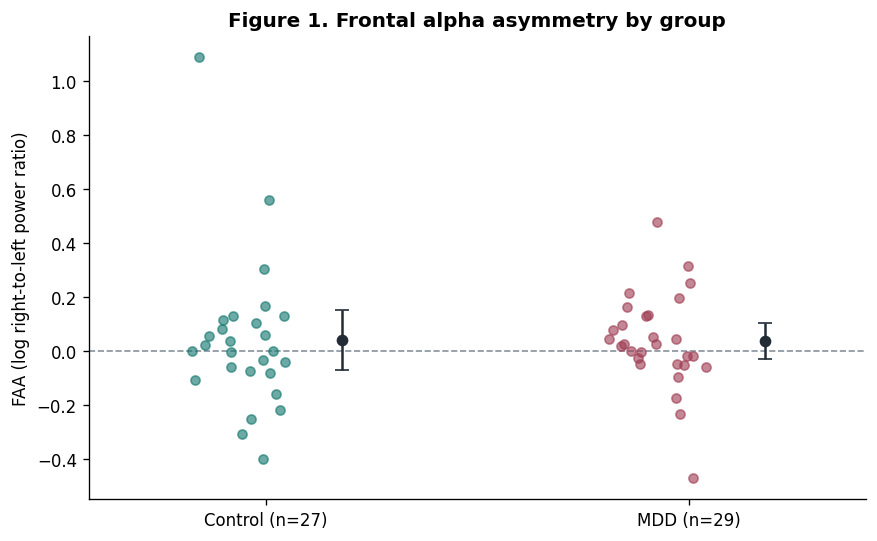

In [6]:
COLORS = {"Control": "#14776F", "MDD": "#9E3E54"}
plt.rcParams.update({
    "axes.spines.right": False, "axes.spines.top": False,
    "axes.titleweight": "bold", "figure.dpi": 120,
})
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(7.2, 4.4), layout="constrained")
for x, group in enumerate(GROUPS):
    scores = features.loc[features["group"] == group, "faa"].to_numpy()
    jitter = rng.uniform(-0.12, 0.12, len(scores))
    ax.scatter(x + jitter - 0.07, scores, color=COLORS[group], alpha=0.62, s=30)
    mean, sd = scores.mean(), scores.std(ddof=1)
    error = stats.t.ppf(0.975, len(scores) - 1) * sd / np.sqrt(len(scores))
    ax.errorbar(x + 0.18, mean, yerr=error, color="#222C37", fmt="o", capsize=4)
ax.axhline(0, linestyle="--", color="#88919D", linewidth=1, zorder=0)
ax.set_xticks(range(len(GROUPS)), [
    f"{group} (n={sum(features['group'] == group)})" for group in GROUPS
])
ax.set(xlim=(-0.42, 1.42), ylabel="FAA (log right-to-left power ratio)",
       title="Figure 1. Frontal alpha asymmetry by group")
fig.savefig(OUTPUT / "figure_1_faa.png", dpi=180)
plt.show()

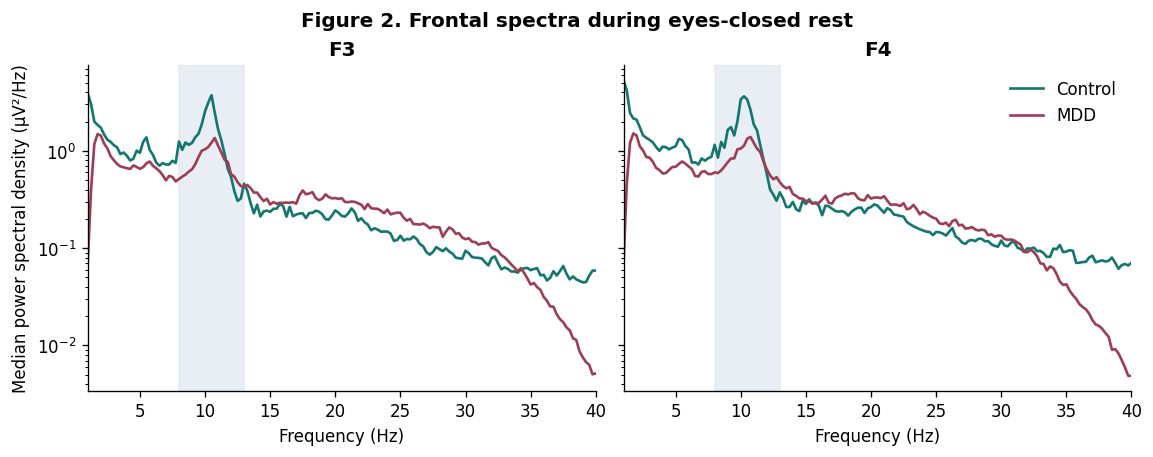

In [7]:
spectra_array = np.stack(spectra)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.7), sharey=True, layout="constrained")
for electrode, ax in zip(("F3", "F4"), axes, strict=True):
    ax.axvspan(8, 13, color="#DBE4ED", alpha=0.6, zorder=0)
    channel_psd = spectra_array[:, CHANNELS.index(electrode), :]
    for group in GROUPS:
        rows = (features["group"] == group).to_numpy()
        # Participant medians are computed at each frequency.
        median = np.median(channel_psd[rows], axis=0) * 1e12
        ax.semilogy(frequencies, median, label=group, color=COLORS[group], linewidth=1.6)
    ax.set(xlabel="Frequency (Hz)", title=electrode, xlim=(1, 40))
axes[0].set_ylabel("Median power spectral density (µV²/Hz)")
axes[1].legend(frameon=False)
fig.suptitle("Figure 2. Frontal spectra during eyes-closed rest", weight="bold")
fig.savefig(OUTPUT / "figure_2_spectra.png", dpi=180)
plt.show()

## 4. Exploratory classification

Use all 76 log band-power features in an L2-regularized logistic regression with the default strength (C = 1). Standardization is fitted inside each training fold. Evaluate on a single seeded, shuffled stratified five-fold partition. Report mean fold accuracy, balanced accuracy and ROC AUC, with sample SD across folds as a measure of spread. Compare against a majority-class predictor fitted on each training fold and against a label-permutation null for balanced accuracy. The permuted labels are stratified again using the same splitting procedure. There is no model tuning or external test cohort.

The source EDFs have either 20 or 22 channels, including auxiliary channels excluded from the EEG model. As a post hoc confounding check, fit a balanced depth-one decision tree using the source channel count alone on the same folds. Also re-evaluate the spectral model in the 20-channel source subgroup, which contains both labels. This subgroup analysis has fewer controls and estimates performance on a different sample.

In [8]:
columns = [f"log_{band}_{channel}" for band in BANDS for channel in CHANNELS]
X = features[columns].to_numpy()
y = (features["group"] == "MDD").astype(int).to_numpy()
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
classifier = make_pipeline(
    StandardScaler(), LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)
)
metrics = ("accuracy", "balanced_accuracy", "roc_auc")
with threadpool_limits(limits=1):
    cv_scores = cross_validate(classifier, X, y, scoring=metrics, cv=splitter, error_score="raise")
    score, permuted_scores, permutation_p = permutation_test_score(
        classifier, X, y, cv=splitter, scoring="balanced_accuracy",
        n_permutations=N_PERMUTATIONS, random_state=SEED, n_jobs=1,
    )
folds = pd.DataFrame({metric: cv_scores[f"test_{metric}"] for metric in metrics})
folds.insert(0, "test_n", [len(test) for _, test in splitter.split(X, y)])
folds["majority_accuracy"] = [
    np.mean(y[test] == np.bincount(y[train]).argmax())
    for train, test in splitter.split(X, y)
]
assert np.isclose(score, folds["balanced_accuracy"].mean())
folds.index = pd.Index(range(1, 6), name="fold")
cv_summary = folds.drop(columns="test_n").agg(["mean", "std"]).T
display(folds.round(4))
display(cv_summary.round(4))
print(f"Balanced-accuracy permutation p = {permutation_p:.3f} "
      f"({N_PERMUTATIONS} permutations; null mean {permuted_scores.mean():.3f}).")

source_count = features[["subject"]].merge(
    qc[["subject", "source_channels"]], on="subject", validate="one_to_one"
)["source_channels"].to_numpy()
layout_counts = pd.crosstab(features["group"], source_count)
display(layout_counts)
layout_only = DecisionTreeClassifier(max_depth=1, class_weight="balanced", random_state=SEED)
same_layout = source_count == 20
diagnostics = {}
with threadpool_limits(limits=1):
    for label, model, predictors, labels in (
        ("Source channel count only", layout_only, source_count[:, None], y),
        ("EEG model, 20-channel source only", classifier, X[same_layout], y[same_layout]),
    ):
        checks = cross_validate(model, predictors, labels, scoring=metrics, cv=splitter,
                                error_score="raise")
        diagnostics[label] = {
            "n_control": int((labels == 0).sum()),
            "n_mdd": int((labels == 1).sum()),
            **{metric: float(checks[f"test_{metric}"].mean()) for metric in metrics},
        }
diagnostic_table = pd.DataFrame.from_dict(diagnostics, orient="index")
display(diagnostic_table.round(4))

Balanced-accuracy permutation p = 0.001 (999 permutations; null mean 0.504).


,test_n,accuracy,balanced_accuracy,roc_auc,majority_accuracy
fold,,,,,
1,12,0.7500,0.7500,0.8889,0.5000
2,11,0.9091,0.9167,0.9667,0.4545
3,11,0.7273,0.7167,0.7000,0.5455
4,11,0.7273,0.7333,0.9000,0.5455
5,11,1.0000,1.0000,1.0000,0.5455


,mean,std
accuracy,0.8227,0.1249
balanced_accuracy,0.8233,0.1273
roc_auc,0.8911,0.1164
majority_accuracy,0.5182,0.0407


col_0,20,22
group,,
Control,5,22
MDD,28,1


,n_control,n_mdd,accuracy,balanced_accuracy,roc_auc
Source channel count only,27,29,0.8909,0.8867,0.8867
"EEG model, 20-channel source only",5,28,0.9048,0.7833,0.9200


## 5. Export the audit trail

The outputs include file-level provenance, participant-level quality checks and features, primary and sensitivity results, classifier results, and figures. All observations are derived from the public dataset. The repository or submission copy can retain the notebook and scientific report while excluding the EDF cache.

In [9]:
manifest.to_csv(OUTPUT / "source_manifest.csv", index=False)
qc.to_csv(OUTPUT / "quality_control.csv", index=False)
features.to_csv(OUTPUT / "participant_features.csv", index=False)
contrast_table.to_csv(OUTPUT / "faa_contrasts.csv", index_label="analysis")
folds.to_csv(OUTPUT / "classifier_folds.csv")
cv_summary.to_csv(OUTPUT / "classifier_summary.csv", index_label="metric")
diagnostic_table.to_csv(OUTPUT / "classifier_layout_diagnostics.csv", index_label="analysis")
np.save(OUTPUT / "permutation_balanced_accuracy.npy", permuted_scores, allow_pickle=False)
(OUTPUT / "run_summary.json").write_text(json.dumps({
    "dataset_doi": ARTICLE_DOI,
    "versions": versions,
    "contrasts": contrasts,
    "classifier_layout_diagnostics": diagnostics,
    "classifier_permutations": N_PERMUTATIONS,
    "classifier_permutation_p": permutation_p,
    "classifier_null_mean": float(permuted_scores.mean()),
}, indent=2), encoding="utf-8")

primary = next(iter(contrasts.values()))
print(f"Primary analysis: {primary['n_mdd']} MDD and {primary['n_control']} controls.")
print(f"FAA difference (MDD minus control) = {primary['delta']:+.4f} log units "
      f"(95% CI {primary['ci_low']:+.4f} to {primary['ci_high']:+.4f}).")
print(f"Welch t({primary['df']:.2f}) = {primary['t']:.3f}, "
      f"p = {primary['p']:.4f}; Hedges' g = {primary['hedges_g']:+.3f}.")
print(f"Exploratory balanced accuracy = {score:.1%}.")

Primary analysis: 29 MDD and 27 controls.
FAA difference (MDD minus control) = -0.0059 log units (95% CI -0.1332 to +0.1214).
Welch t(42.84) = -0.094, p = 0.9259; Hedges' g = -0.025.
Exploratory balanced accuracy = 82.3%.


## Interpretation

Use the primary effect estimate and confidence interval to describe the size and uncertainty of the difference. Positive FAA indicates higher right than left alpha power at the two scalp electrodes. Reference choice, residual artifacts, and uncontrolled differences between clinical and control participants can affect interpretation. A group comparison and an internally cross-validated classifier address different questions. Both results are specific to this dataset and pipeline.